# Monopsony: Marginal Cost of Labour

A **non-discriminating monopsonist** faces the upward-sloping market labour supply curve $w=w(E)$ and must pay *all* workers the same wage.

## 1. Derivation of $MC_E = w\,(1+1/\sigma)$

Total labour cost is $TC(E) = w(E)\,E$. By the product rule

$$MC_E=\frac{dTC}{dE}=w+E\,\frac{dw}{dE}.$$

The extra worker costs the wage $w$, plus the wage increase $dw/dE$ that must be paid to all $E$ workers already employed.

The supply elasticity is $\sigma=\dfrac{dE}{dw}\dfrac{w}{E}$, hence $\dfrac{dw}{dE}=\dfrac{1}{\sigma}\dfrac{w}{E}$. Substituting,

$$MC_E=w+E\cdot\frac{1}{\sigma}\frac{w}{E}=w+\frac{w}{\sigma}\quad\Longrightarrow\quad \boxed{MC_E=w\left(1+\frac1\sigma\right)}$$

**Remarks**

* $\sigma>0\Rightarrow MC_E>w$: the marginal cost curve lies above the supply curve.
* $\sigma\to\infty$ (competitive firm, horizontal supply) gives $MC_E\to w$.
* Profit maximisation, $VMP_E=MC_E$, gives $\dfrac{VMP_E-w}{w}=\dfrac1\sigma$: the less elastic supply is, the further the wage falls below the marginal product.
* Linear supply $w=\alpha+\beta E$: $MC_E=\alpha+2\beta E$, twice the slope of supply.

## 2. Symbolic check

In [1]:
import sys
sys.path.insert(0, ".")
import numpy as np, sympy as sp
import matplotlib.pyplot as plt
from common import BLUE, RED, GREEN, GREY, ORANGE

E, al, be = sp.symbols("E alpha beta", positive=True)
w = al + be * E                              # linear inverse supply
MC = sp.diff(w * E, E)                       # d(wE)/dE
sigma = (1 / sp.diff(w, E)) * w / E          # elasticity (dE/dw) * w/E
print("MC_E          =", sp.simplify(MC))
print("sigma         =", sp.simplify(sigma))
print("w(1 + 1/sigma) - MC_E =", sp.simplify(w * (1 + 1 / sigma) - MC))
assert sp.simplify(w * (1 + 1 / sigma) - MC) == 0

MC_E          = 2*E*beta + alpha
sigma         = 1 + alpha/(E*beta)
w(1 + 1/sigma) - MC_E = 0


## 3. Numerical example

Supply $w=5+0.1E$, demand (value of marginal product) $VMP=40-0.1E$.

* Competitive market: $5+0.1E=40-0.1E$, so $E_c=175$, $w_c=22.5$.
* Monopsony: $MC_E=5+0.2E=40-0.1E$, so $E_m=116.7$; the wage is read **off the supply curve**: $w_m=16.67$.

competitive: E=175.0, w=22.50
monopsony:   E=116.7, w=16.67, sigma=1.43, MC=28.33=VMP=28.33


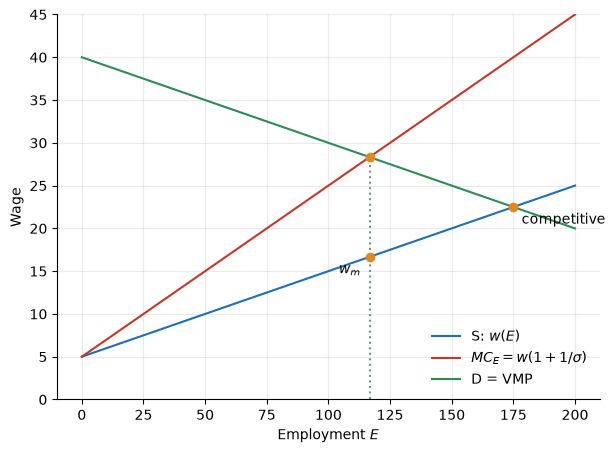

In [2]:
alpha, beta = 5.0, 0.1
supply = lambda e: alpha + beta * e
MCE = lambda e: alpha + 2 * beta * e
VMP = lambda e: 40 - 0.1 * e

Ec = (40 - alpha) / (beta + 0.1);  wc = supply(Ec)
Em = (40 - alpha) / (2 * beta + 0.1);  wm = supply(Em)
sig_m = wm / (beta * Em)                       # elasticity at the monopsony point
assert np.isclose(MCE(Em), wm * (1 + 1 / sig_m))   # formula holds numerically
assert np.isclose((VMP(Em) - wm) / wm, 1 / sig_m)  # markdown rule
print(f"competitive: E={Ec:.1f}, w={wc:.2f}")
print(f"monopsony:   E={Em:.1f}, w={wm:.2f}, sigma={sig_m:.2f}, MC={MCE(Em):.2f}=VMP={VMP(Em):.2f}")

e = np.linspace(0, 200, 200)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(e, supply(e), color=BLUE, label="S: $w(E)$")
ax.plot(e, MCE(e), color=RED, label="$MC_E=w(1+1/\\sigma)$")
ax.plot(e, VMP(e), color=GREEN, label="D = VMP")
ax.plot([Em, Em], [0, VMP(Em)], color=GREY, ls=":")
ax.scatter([Ec, Em, Em], [wc, wm, VMP(Em)], color=ORANGE, zorder=3)
ax.annotate("competitive", (Ec, wc), textcoords="offset points", xytext=(6, -12))
ax.annotate("$w_m$", (Em, wm), textcoords="offset points", xytext=(-22, -12))
ax.set_xlabel("Employment $E$"); ax.set_ylabel("Wage"); ax.set_ylim(0, 45); ax.legend()
plt.show()